## Análisis de Datos Meteorológicos con una API Pública
Obtener datos del clima de una ciudad usando la API de Open-Meteo (https://open-meteo.com/) y mostrar el pronóstico para Bilbao.

* Haz una petición a la API para que devuelva el pronóstico de las temperaturas para una semana en Bilbao. Tip: el parámetro correspondiente en el query es `temperature_2m` además de la latitud y la longitud.
* Procesa la respuesta en formato JSON para obtener dos listas: una con la lista de temperaturas y otra con las fechas-horas correspondientes.
* Crea un DataFrame con esas dos columnas: `Hora` y `Temperatura`
* Elige la gráfica adecuada y visualiza el pronóstico de temperaturas.

Para crear la variable `Hora` del DataFrame puedes introducir directamente la lista que se obtiene del campo `data["hourly"]["time"]` o procesar esa lista mediante el siguiente código:

`hours = pd.date_range(start=lista_de_horas, periods=len(temps), freq="H")`

In [1]:
import requests


# Coordenadas de Kuna en Bilbao
latitude = 43.2540
longitude = -2.9230


url = f"https://api.open-meteo.com/v1/forecast?"  # Aquí vienen el resto de los parámetros

In [2]:
%pip install requests

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
# 1. Haz una petición a la API para que devuelva el pronóstico de las temperaturas para una semana en Bilbao. Tip: el parámetro correspondiente en el query es `temperature_2m` además de la latitud y la longitud.
meteo = requests.get(url, params={
    "latitude": latitude,
    "longitude": longitude,
    "hourly": "temperature_2m",
})

In [4]:
pronostico = meteo.json()   #Hago la petición a la API y me devuelve un diccionario con el pronóstico. Paso la respuesta a formato JSON para poder trabajar con ella.
pronostico

{'latitude': 43.25,
 'longitude': -2.92,
 'generationtime_ms': 0.09906291961669922,
 'utc_offset_seconds': 0,
 'timezone': 'GMT',
 'timezone_abbreviation': 'GMT',
 'elevation': 14.0,
 'hourly_units': {'time': 'iso8601', 'temperature_2m': '°C'},
 'hourly': {'time': ['2026-11-09T00:00',
   '2026-11-09T01:00',
   '2026-11-09T02:00',
   '2026-11-09T03:00',
   '2026-11-09T04:00',
   '2026-11-09T05:00',
   '2026-11-09T06:00',
   '2026-11-09T07:00',
   '2026-11-09T08:00',
   '2026-11-09T09:00',
   '2026-11-09T10:00',
   '2026-11-09T11:00',
   '2026-11-09T12:00',
   '2026-11-09T13:00',
   '2026-11-09T14:00',
   '2026-11-09T15:00',
   '2026-11-09T16:00',
   '2026-11-09T17:00',
   '2026-11-09T18:00',
   '2026-11-09T19:00',
   '2026-11-09T20:00',
   '2026-11-09T21:00',
   '2026-11-09T22:00',
   '2026-11-09T23:00',
   '2026-11-10T00:00',
   '2026-11-10T01:00',
   '2026-11-10T02:00',
   '2026-11-10T03:00',
   '2026-11-10T04:00',
   '2026-11-10T05:00',
   '2026-11-10T06:00',
   '2026-11-10T07:00',
 

In [5]:
# 2. Procesa la respuesta en formato JSON para obtener dos listas: una con la lista de temperaturas y otra con las fechas-horas correspondientes.
temperaturas = pronostico["hourly"]["temperature_2m"]
fechas_horas = pronostico["hourly"]["time"]

In [6]:
temperaturas, fechas_horas

([18.8,
  18.4,
  19.4,
  19.5,
  19.9,
  20.2,
  19.9,
  18.8,
  19.1,
  19.6,
  20.3,
  20.8,
  21.1,
  20.7,
  21.3,
  21.5,
  22.0,
  21.7,
  21.1,
  20.2,
  20.3,
  20.4,
  20.5,
  20.5,
  20.8,
  21.0,
  21.0,
  20.6,
  20.2,
  20.9,
  21.0,
  20.4,
  19.9,
  20.5,
  21.3,
  22.2,
  22.8,
  23.0,
  22.6,
  22.0,
  21.5,
  21.2,
  19.2,
  18.9,
  20.3,
  20.2,
  19.7,
  19.7,
  19.4,
  19.3,
  19.1,
  18.9,
  18.7,
  18.8,
  18.7,
  18.7,
  19.3,
  20.2,
  21.4,
  22.4,
  23.2,
  23.4,
  22.9,
  22.6,
  22.1,
  21.2,
  20.5,
  20.1,
  19.7,
  19.2,
  18.9,
  19.0,
  19.0,
  19.0,
  18.9,
  18.1,
  17.2,
  16.9,
  16.7,
  16.5,
  16.4,
  16.9,
  17.3,
  18.0,
  18.1,
  17.0,
  16.6,
  17.1,
  17.3,
  17.2,
  17.0,
  16.9,
  17.0,
  16.7,
  16.3,
  16.3,
  16.3,
  16.2,
  16.4,
  15.9,
  14.9,
  14.2,
  13.6,
  12.9,
  12.7,
  12.5,
  12.5,
  12.4,
  12.4,
  12.4,
  12.4,
  12.3,
  12.2,
  12.0,
  11.7,
  11.1,
  10.4,
  9.7,
  9.2,
  8.8,
  8.3,
  7.8,
  7.3,
  6.6,
  5.4,
  3.9,
 

In [7]:
# 3. Crea un DataFrame con esas dos columnas: `Hora` y `Temperatura`
import pandas as pd

In [8]:
df = pd.DataFrame({
    "Hora": fechas_horas,
    "Temperatura": temperaturas
})

In [9]:
df.head()

,Hora,Temperatura
0,2026-11-09T00:00,18.8
1,2026-11-09T01:00,18.4
2,2026-11-09T02:00,19.4
3,2026-11-09T03:00,19.5
4,2026-11-09T04:00,19.9


In [10]:
df.tail()

,Hora,Temperatura
163,2026-11-15T19:00,15.9
164,2026-11-15T20:00,15.6
165,2026-11-15T21:00,15.3
166,2026-11-15T22:00,15.0
167,2026-11-15T23:00,14.8


In [11]:
# 4. Elige la gráfica adecuada y visualiza el pronóstico de temperaturas.
import matplotlib.pyplot as plt

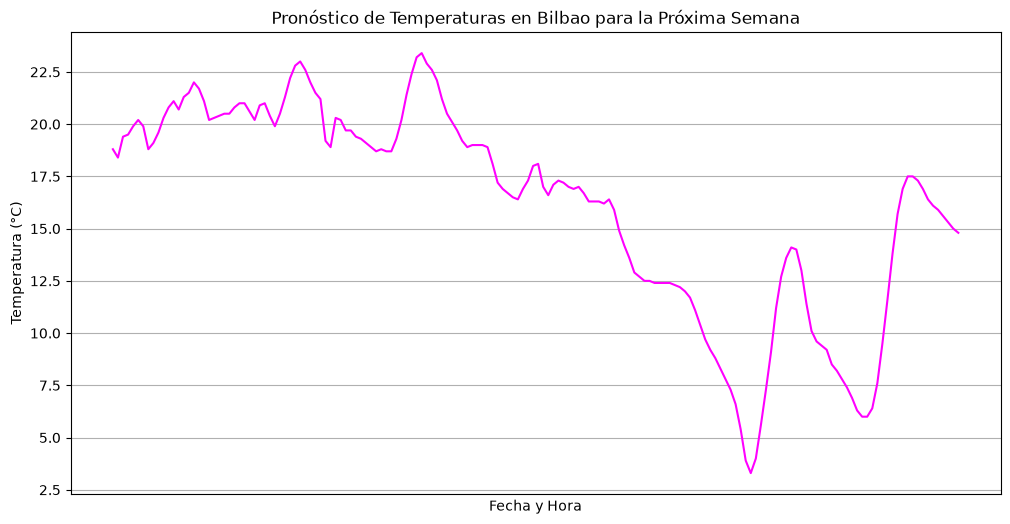

In [12]:
plt.figure(figsize=(12, 6))
plt.plot(df["Hora"], df["Temperatura"], linestyle='-', color ='magenta')
plt.title("Pronóstico de Temperaturas en Bilbao para la Próxima Semana")    
plt.xlabel("Fecha y Hora")
plt.ylabel("Temperatura (°C)")
plt.xticks([])   #quito los ticks del eje x para que no se vea tan saturado
plt.grid()